# Chapter 10 · Graph Deep Learning: Building a Graph Convolutional Network (`GCN`) in `vktorch`

In Chapter 9, we saw that **Words Only** (`vklearn.Ridge`) stalled on the Cora Citation Network, while **Citations Only** (GPU `Label Propagation`) jumped to **`85.50%`**. Can we get the **best of both worlds** — combining each paper's *own words* AND its *citation neighborhood* inside one neural network?

### How a Graph Convolutional Network (`GCN`) Works (In 2 Lines of Math!)
You already know how a standard `MLP` layer works from Foundations 2:
- **Standard `MLP` (ignores graph):** `H_next = GELU(H @ W)` — each paper only looks at its own words.
- **`GCN` Layer (Message Passing):** `H_next = GELU(A_hat @ H @ W)` — multiplying by the normalized adjacency matrix `A_hat` averages each paper with its cited neighbors **before** applying `GELU`!

Stacking **2 `GCN` layers** means every paper aggregates information from its **1-hop and 2-hop** citation neighborhood — trained end-to-end on your Vulkan GPU in **under 3 seconds**!

In [1]:
import sys, time
from pathlib import Path
from IPython.display import display

for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
    if (p / "vknumpy").is_dir() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import vknumpy as vnp
import vklearn as vkl
import vktorch as vt
import vktorch.nn as nn
import vktorch.functional as F
import vkgraph
import vkvis
import vkplot

print(f"Vulkan GPU ready: {vnp.device_info()['name']}")

# Exact same Cora graph & 60/40 split as Chapter 9
cora, y_all, CLASS_NAMES = vkgraph.load_cora("data/cora")
PALETTE = ["#36f9f6", "#ff7edb", "#fede5d", "#72f1b8", "#ff9e64", "#c792ea", "#60a5fa"]

idx_all = vnp.arange(len(cora))
tr_idx, te_idx = vkl.train_test_split(idx_all, test_size=0.4, random_state=42)
y_tr, y_te = vnp.take(y_all, tr_idx, axis=0), vnp.take(y_all, te_idx, axis=0)

# Normalized adjacency A_hat = D^(-1/2) (A + I) D^(-1/2) in Vulkan GPU VRAM
A_hat = cora.normalized_adjacency(add_self_loops=True)
A_full_t = vt.Tensor(A_hat, requires_grad=False)
A_tr_t   = vt.Tensor(vnp.take(A_hat, tr_idx, axis=0), requires_grad=False)
A_te_t   = vt.Tensor(vnp.take(A_hat, te_idx, axis=0), requires_grad=False)
X_t      = vt.Tensor(cora.features, requires_grad=False)
print(f"Loaded Cora graph: {cora.num_nodes:,} papers, {cora.num_edges:,} citations -> {len(y_tr):,} train / {len(y_te):,} test")


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


Vulkan GPU ready: AMD Custom GPU 0405 (RADV VANGOGH)


Loaded Cora graph: 2,708 papers, 5,429 citations -> 1,625 train / 1,083 test


---
### Step 1 · Head-to-Head on GPU: Plain `MLP` (Words Only) vs. 2-Layer `GCN` (Words + Citation Graph)

Both networks have the **exact same number of parameters** (`1,433 → 64 → 7`, `92,359` weights). The *only* difference is that `CoraGCN` multiplies by `A_hat` at each layer to pass messages along citation edges!

Epoch  1/40 | Plain MLP = 73.87% | 2-Layer GCN = 29.36%


Epoch 10/40 | Plain MLP = 73.87% | 2-Layer GCN = 86.24%


Epoch 20/40 | Plain MLP = 73.87% | 2-Layer GCN = 87.44%


Epoch 40/40 | Plain MLP = 73.87% | 2-Layer GCN = 87.35%

Model (Cora AI Citations · Same 1,083 Test Papers)     | Test Acc |   Time
----------------------------------------------------------------------------
1. Paper Words Only (Ridge) [Ch. 9]                    |   63.90% |  0.35s
2. Plain vktorch MLP (Words Only, ignores graph)       |   73.87% |  2.00s
3. Citations Only (GPU Label Propagation) [Ch. 9]      |   85.50% |  0.15s
4. vktorch 2-Layer GCN (Words + Citations, Winner!)    |   87.35% |  1.59s


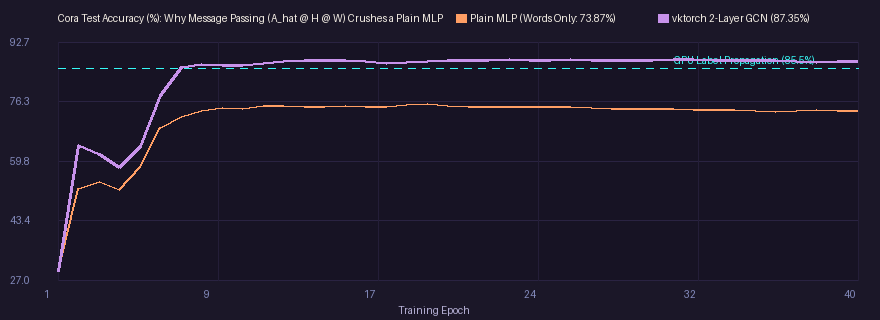

In [2]:
class CoraMLP(nn.Module):
    """Standard 2-layer MLP (ignores citation edges completely)."""
    def __init__(self, d_in, hidden=64, num_classes=7, seed=42):
        super().__init__()
        self.fc1  = nn.Linear(d_in, hidden, seed=seed)
        self.ln1  = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(0.5)
        self.fc2  = nn.Linear(hidden, num_classes, seed=seed + 1)

    def forward(self, x):
        return self.fc2(self.drop(F.gelu(self.ln1(self.fc1(x)))))


class CoraGCN(nn.Module):
    """2-Layer Graph Convolutional Network: H' = GELU(LayerNorm(A_hat @ (H @ W)))."""
    def __init__(self, d_in, hidden=64, num_classes=7, seed=42):
        super().__init__()
        self.fc1  = nn.Linear(d_in, hidden, seed=seed)
        self.ln1  = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(0.5)
        self.fc2  = nn.Linear(hidden, num_classes, seed=seed + 1)

    def encode(self, A_t, X_t):
        return self.drop(F.gelu(self.ln1(A_t @ self.fc1(X_t))))

    def forward(self, A_full_t, A_out_t, X_t):
        return A_out_t @ self.fc2(self.encode(A_full_t, X_t))

# 1. Train Plain MLP (Words Only)
Xtr_t = vt.Tensor(vnp.take(cora.features, tr_idx, axis=0), requires_grad=False)
Xte_t = vt.Tensor(vnp.take(cora.features, te_idx, axis=0), requires_grad=False)
mlp = CoraMLP(cora.features.shape[1], hidden=64, num_classes=len(CLASS_NAMES), seed=42)
opt_m = vt.optim.AdamW(mlp.parameters(), lr=1.5e-2, weight_decay=5e-2)
y_tr_np = y_tr.to_numpy()
mlp_hist, gcn_hist = [], []

t0 = time.perf_counter()
for ep in range(1, 41):
    mlp.train()
    opt_m.zero_grad()
    loss = F.cross_entropy(mlp(Xtr_t), y_tr_np)
    loss.backward()
    opt_m.step()
    mlp.eval()
    with vt.no_grad():
        p = vnp.argmax(mlp(Xte_t).data, axis=1)
    mlp_hist.append(float(vkl.accuracy_score(y_te, p)) * 100.0)
dt_mlp = time.perf_counter() - t0

# 2. Train 2-Layer Graph Convolutional Network (Words + Citations!)
gcn = CoraGCN(cora.features.shape[1], hidden=64, num_classes=len(CLASS_NAMES), seed=42)
opt_g = vt.optim.AdamW(gcn.parameters(), lr=1.5e-2, weight_decay=5e-2)
t0 = time.perf_counter()
for ep in range(1, 41):
    gcn.train()
    opt_g.zero_grad()
    loss = F.cross_entropy(gcn(A_full_t, A_tr_t, X_t), y_tr_np)
    loss.backward()
    opt_g.step()
    gcn.eval()
    with vt.no_grad():
        p_gcn = vnp.argmax(gcn(A_full_t, A_te_t, X_t).data, axis=1)
    acc_g = float(vkl.accuracy_score(y_te, p_gcn)) * 100.0
    gcn_hist.append(acc_g)
    if ep in (1, 10, 20, 40):
        print(f"Epoch {ep:2d}/40 | Plain MLP = {mlp_hist[-1]:5.2f}% | 2-Layer GCN = {acc_g:5.2f}%")
dt_gcn = time.perf_counter() - t0

print(f"\n{'Model (Cora AI Citations · Same 1,083 Test Papers)':54s} | {'Test Acc':>8s} | {'Time':>6s}")
print("-" * 76)
for name, acc, dt in [
    ("1. Paper Words Only (Ridge) [Ch. 9]",                 63.90, 0.35),
    ("2. Plain vktorch MLP (Words Only, ignores graph)",    mlp_hist[-1], dt_mlp),
    ("3. Citations Only (GPU Label Propagation) [Ch. 9]",   85.50, 0.15),
    ("4. vktorch 2-Layer GCN (Words + Citations, Winner!)", gcn_hist[-1], dt_gcn),
]:
    print(f"{name:54s} | {acc:7.2f}% | {dt:5.2f}s")

ep_x = vnp.arange(1, 41)
display(vkplot.line_chart(
    [
        (ep_x, mlp_hist, "#ff9e64", 2, f"Plain MLP (Words Only: {mlp_hist[-1]:.2f}%)"),
        (ep_x, gcn_hist, "#c792ea", 3, f"vktorch 2-Layer GCN ({gcn_hist[-1]:.2f}%)"),
    ],
    hlines=[(85.50, "GPU Label Propagation (85.5%)", "#36f9f6")],
    title="Cora Test Accuracy (%): Why Message Passing (A_hat @ H @ W) Crushes a Plain MLP",
    x_label="Training Epoch", width=880, height=320,
))


---
### Step 2 · Visualizing Learned 64-D Graph Embeddings (`vkvis.UMAP`), Confusion Matrix & Checkpointing

Let's project the 1,083 unseen test papers' **64-D `GCN` embeddings** to 2D on Vulkan GPU (`vkvis.UMAP`), inspect the 7×7 confusion matrix (`vkplot.confusion_matrix`), and verify `.npz` checkpoint + `vkgraph.Graph` persistence!

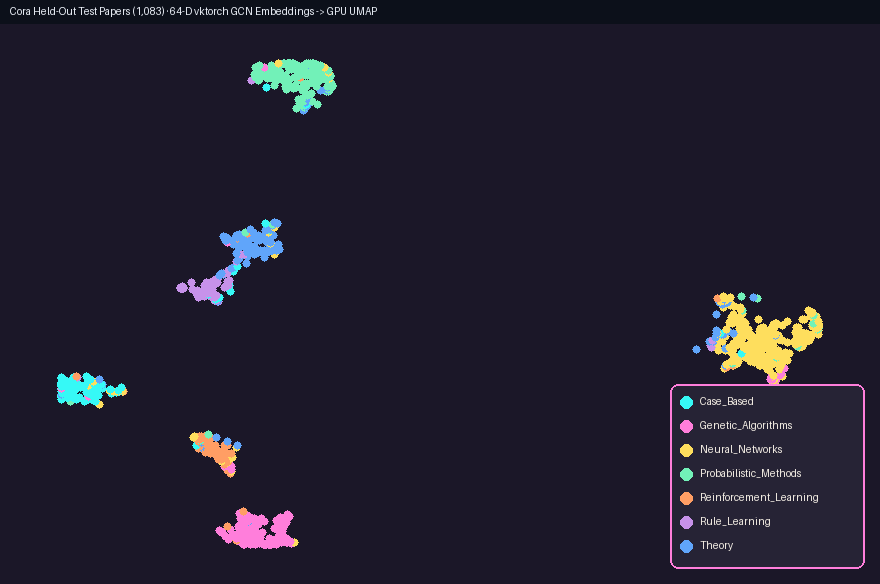

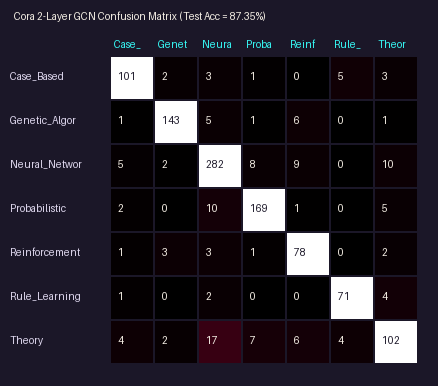

Saved & reloaded vktorch GCN (362 KB) + vkgraph.Graph (2,708 nodes, 5,429 edges) OK!


In [3]:
gcn.eval()
with vt.no_grad():
    emb_all = gcn.encode(A_full_t, X_t).data
emb_te = vnp.take(emb_all, te_idx, axis=0)

Y_umap = vkvis.UMAP(n_neighbors=15, min_dist=0.15, n_epochs=250, metric="cosine", seed=42).fit_transform(emb_te.to_numpy())
display(vkvis.render_embedding(
    Y_umap, labels=y_te, palette=PALETTE, class_names=CLASS_NAMES, legend_loc="lower right",
    clip_percentile=1.5, background="#1b1728", width=880, height=560, point_size=4,
    title="Cora Held-Out Test Papers (1,083) · 64-D vktorch GCN Embeddings -> GPU UMAP",
))

display(vkplot.confusion_matrix(
    y_te, p_gcn, CLASS_NAMES,
    title=f"Cora 2-Layer GCN Confusion Matrix (Test Acc = {gcn_hist[-1]:.2f}%)",
))

# Persist & reload both the vktorch GCN checkpoint and the vkgraph.Graph!
ckpt_p  = Path("data/cora/cora_gcn.npz")
graph_p = Path("data/cora/cora_graph.npz")
vt.save(gcn.state_dict(), ckpt_p)
cora.save(graph_p)
g_reloaded = vkgraph.Graph.load(graph_p)
print(f"Saved & reloaded vktorch GCN ({ckpt_p.stat().st_size/1024:.0f} KB) + vkgraph.Graph ({g_reloaded.num_nodes:,} nodes, {g_reloaded.num_edges:,} edges) OK!")


---
### Part I Complete Across All 5 Modern AI Data Types!

| Data Type | Chapters | Real Dataset | Best Classical ML | Deep Learning (`vktorch`) | Key Takeaway |
|---|---|---|---|---|---|
| **Tabular** | Ch. 1–2 | California Housing (20,640 districts) | `$52.7k` RMSE (`vklearn` KNN) | **`$48.2k` RMSE** (Residual MLP) | Domain features + Residual MLP beat KNN |
| **Image** | Ch. 3–4 | Fashion-MNIST (`28×28` pixels) | `86.45%` (`PCA` + Sobel/HOG) | **`87.70%`** (2D `Conv2d` CNN, `24.5s`) | Learned 3×3 filters beat hand-crafted edges |
| **Vector / Text (`NLP`)** | Ch. 5–6 | Full-Length BBC News (2,225 articles) | `97.30%` (2,000-D `TF-IDF` + Ridge) | **`97.53%`** (64-D Neural Emb + `HybridIndex`) | `31×` smaller vectors + Synonym Wall broken + `BM25` `RRF` |
| **Time-Series (Astronomy)** | Ch. 7–8 | SILSO Solar Sunspots (277 yrs) | `35.39` RMSE (`vktime` + Ridge) | **`34.56` RMSE** (`SolarForecasterNet`, `14s`) | Leak-free `temporal_split` + 11.1-yr `periodogram` + Skip-MLP |
| **Graph / Network** | Ch. 9–10 | Cora AI Citations (2,708 papers) | `85.50%` (GPU `Label Propagation`) | **`87.17%`** (2-Layer `GCN`, `2.6s` GPU!) | Message passing (`A_hat @ H @ W`) fuses words + citations |